# 1. Data Pipeline

In [ ]:
import pandas as pd
import kagglehub
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from torch.utils.data import TensorDataset, DataLoader
from sentence_transformers import SentenceTransformer

def load_data():
  df = pd.read_parquet("hf://datasets/lavita/MedQuAD/data/train-00000-of-00001-e36383d177026d53.parquet")

  return df

def load_data2():
  path = kagglehub.dataset_download("pythonafroz/medquad-medical-question-answer-for-ai-research")
  data_dir = Path(path)
  df = pd.read_csv(data_dir / "medquad.csv")

  return df

def mergeAnswers(df1, df2):
  df3 = df1.copy()
  lookup = (
      df2.loc[df2["answer"].notna(), ["question", "answer"]]
        .drop_duplicates(subset="question")
        .set_index("question")["answer"]
  )
  missing = df3["answer"].isna() | df3["answer"].fillna("").str.strip().eq("")
  df3.loc[missing, "answer"] = df3.loc[missing, "question"].map(lookup)

  return df3

def resolving_missing_values_of_synonyms(df1, df2):
  synonyms_from_df2 = (
    df2.dropna(subset=["synonyms"])
       .drop_duplicates(subset=["question"])
       .set_index("question")["synonyms"]
)
  missing = df1["synonyms"].isna()
  df1.loc[missing, "synonyms"] = (
      df1.loc[missing, "question"].map(synonyms_from_df2)
  )
  return df1

def preprocess(df1, df2):
  # the answer columns has many missing values, so I merged two different published dataset (both are the same but with different sorces) to minimize the losses of info
  df = mergeAnswers(df1, df2)
  # around 15k value in the category column is None, so will fill them with the "Other" Value
  df["category"] = df["category"].fillna("Other")
  #there are some unuseful columns, so I throw it in the trash :), umls_semantic_group values is either disorder or None (unuseful!)
  usefulness_columns = ["document_id", "document_url", "umls_cui", "umls_semantic_types", "umls_semantic_group"]
  df = df.drop(columns = usefulness_columns)
  #if the record does not provide an answer value, it is useless so we will just drop it
  df.dropna(subset = "answer", inplace=True)
  #the merged answers are copies of question/answer pairs we already have, so we drop the duplicates
  df["answer"] = df["answer"].str.strip()
  df = df.drop_duplicates(subset = ["question", "answer"])
  #stratify needs enough records in each question_type ("support groups" has only 1 record)
  counts = df["question_type"].value_counts()
  df = df[df["question_type"].isin(counts[counts >= 10].index)]
  #the kaggle dataset has no synonyms column, and synonyms is not an input to the model, so this step is skipped
  # df = resolving_missing_values_of_synonyms(df, df2)
  return df

def show_samples(df):
  samples = df.groupby("question_type").head(1)
  for i, row in samples.iterrows():
    print("[" + row["question_type"] + "]")
    print("Q:", row["question"])
    print("A:", row["answer"][:150], "...")
    print()

  return samples

def split(df):
  X = df.drop(columns = "answer")
  y = df["answer"]
  stratify_column = df["question_type"]
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, stratify = stratify_column, random_state = 42)
  X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size = 0.2, stratify = X_train["question_type"], random_state = 42)

  return X_train, X_test, X_val, y_train, y_test, y_val

def embed(texts, model):
  #the encoder is pretrained and frozen, it turns each text into a vector of 384 numbers
  vectors = model.encode(list(texts), batch_size = 64, show_progress_bar = True)

  return vectors

def encode_labels(X_train, X_test, X_val):
  label_encoder = LabelEncoder()
  train_labels = label_encoder.fit_transform(X_train["question_type"])
  test_labels = label_encoder.transform(X_test["question_type"])
  val_labels = label_encoder.transform(X_val["question_type"])

  return train_labels, test_labels, val_labels, label_encoder

def normalize(train, test, val):
  scaler = StandardScaler()
  train = scaler.fit_transform(train)
  test = scaler.transform(test)
  val = scaler.transform(val)

  return train, test, val, scaler

def to_tensors(X, y):
  X = torch.tensor(X, dtype = torch.float32)
  y = torch.tensor(y, dtype = torch.float32)

  return X, y

def make_loaders(X_train, y_train, X_test, y_test, X_val, y_val, batch_size = 64):
  #only the training data is shuffled
  train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size = batch_size, shuffle = True)
  test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size = batch_size, shuffle = False)
  val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size = batch_size, shuffle = False)

  return train_loader, test_loader, val_loader


df1 = load_data()
df2 = load_data2()
df = preprocess(df1, df2)
print("clean shape:", df.shape)
samples = show_samples(df)

X_train, X_test, X_val, y_train, y_test, y_val = split(df)
print("train:", len(X_train), " test:", len(X_test), " val:", len(X_val))

model = SentenceTransformer("all-MiniLM-L6-v2")
#input of the MLP is the question, target is the answer
X_train_emb = embed(X_train["question"], model)
X_test_emb = embed(X_test["question"], model)
X_val_emb = embed(X_val["question"], model)
y_train_emb = embed(y_train, model)
y_test_emb = embed(y_test, model)
y_val_emb = embed(y_val, model)

train_labels, test_labels, val_labels, label_encoder = encode_labels(X_train, X_test, X_val)
X_train_emb, X_test_emb, X_val_emb, x_scaler = normalize(X_train_emb, X_test_emb, X_val_emb)
y_train_emb, y_test_emb, y_val_emb, y_scaler = normalize(y_train_emb, y_test_emb, y_val_emb)

X_train_t, y_train_t = to_tensors(X_train_emb, y_train_emb)
X_test_t, y_test_t = to_tensors(X_test_emb, y_test_emb)
X_val_t, y_val_t = to_tensors(X_val_emb, y_val_emb)

train_loader, test_loader, val_loader = make_loaders(X_train_t, y_train_t, X_test_t, y_test_t, X_val_t, y_val_t)
X_batch, y_batch = next(iter(train_loader))
print("one batch:", X_batch.shape, y_batch.shape)

Using Colab cache for faster access to the 'medquad-medical-question-answer-for-ai-research' dataset.
clean shape: (16358, 8)
[information]
Q: What is (are) keratoderma with woolly hair ?
A: Keratoderma with woolly hair is a group of related conditions that affect the skin and hair and in many cases increase the risk of potentially life-th ...

[frequency]
Q: How many people are affected by keratoderma with woolly hair ?
A: Keratoderma with woolly hair is rare; its prevalence worldwide is unknown.  Type I (Naxos disease) was first described in families from the Greek isla ...

[genetic changes]
Q: What are the genetic changes related to keratoderma with woolly hair ?
A: Mutations in the JUP, DSP, DSC2, and KANK2 genes cause keratoderma with woolly hair types I through IV, respectively. The JUP, DSP, and DSC2 genes pro ...

[inheritance]
Q: Is keratoderma with woolly hair inherited ?
A: Most cases of keratoderma with woolly hair have an autosomal recessive pattern of inheritance, which 

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/164 [00:00<?, ?it/s]

Batches:   0%|          | 0/52 [00:00<?, ?it/s]

Batches:   0%|          | 0/41 [00:00<?, ?it/s]

Batches:   0%|          | 0/164 [00:00<?, ?it/s]

Batches:   0%|          | 0/52 [00:00<?, ?it/s]

Batches:   0%|          | 0/41 [00:00<?, ?it/s]

one batch: torch.Size([64, 384]) torch.Size([64, 384])


## 2. MLP

In [ ]:
def build_mlp(hidden_sizes, input_size = 384, output_size = 384, dropout = 0.2):
  layers = []
  previous_size = input_size
  for size in hidden_sizes:
    layers.append(nn.Linear(previous_size, size))
    layers.append(nn.ReLU())
    layers.append(nn.Dropout(dropout))
    previous_size = size
  #the output is the answer embedding (384 real numbers), so the output layer is linear with no activation
  layers.append(nn.Linear(previous_size, output_size))

  return nn.Sequential(*layers) # the * used to unpack the layers array

#neurons: the first layer expands 384 -> 512 to give the network room to learn the question -> answer mapping,
#then the layers get smaller back towards the 384 output
SHALLOW_LAYERS = [512, 256]
DEEP_LAYERS = [512, 512, 384, 384, 256]

print(build_mlp(SHALLOW_LAYERS))
print(build_mlp(DEEP_LAYERS))

Sequential(
  (0): Linear(in_features=384, out_features=512, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=512, out_features=256, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.2, inplace=False)
  (6): Linear(in_features=256, out_features=384, bias=True)
)
Sequential(
  (0): Linear(in_features=384, out_features=512, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=512, out_features=512, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.2, inplace=False)
  (6): Linear(in_features=512, out_features=384, bias=True)
  (7): ReLU()
  (8): Dropout(p=0.2, inplace=False)
  (9): Linear(in_features=384, out_features=384, bias=True)
  (10): ReLU()
  (11): Dropout(p=0.2, inplace=False)
  (12): Linear(in_features=384, out_features=256, bias=True)
  (13): ReLU()
  (14): Dropout(p=0.2, inplace=False)
  (15): Linear(in_features=256, out_features=384, bias=True)
)


## 3. Experiments

In [9]:
device = "cuda" #using colab GPU
EPOCHS = 30
#regularization strength: L2 weight decay, the same for every run (plus dropout 0.2 inside the MLP)
WEIGHT_DECAY = 0.0001
print("regularization strength (weight decay):", WEIGHT_DECAY)

#loss functions
def get_loss(name):
  if name == "MSE": #Mean Squere Error
    return nn.MSELoss()
  if name == "MAE": #Mean Absolute Error
    return nn.L1Loss()
  if name == "Huber": #This loss combine MAE and MSE
    return nn.HuberLoss(delta = 1.0)

#optimizers
def get_optimizer(name, model, lr):
  if name == "SGD":
    return torch.optim.SGD(model.parameters(), lr = lr, momentum = 0.9, weight_decay = WEIGHT_DECAY)
  if name == "RMSprop":
    return torch.optim.RMSprop(model.parameters(), lr = lr, weight_decay = WEIGHT_DECAY)
  if name == "Adam":
    return torch.optim.Adam(model.parameters(), lr = lr, weight_decay = WEIGHT_DECAY)

#common starting learning rate for each optimizer (used in the 3x3 comparison)
DEFAULT_LR = {"SGD": 0.01, "RMSprop": 0.001, "Adam": 0.001}

def run_epoch(model, loader, loss_fn, optimizer = None):
  #with an optimizer the model is trained, without one it is only evaluated
  if optimizer is not None:
    model.train()
  else:
    model.eval()
  total_loss = 0
  total_squared_error = 0
  count = 0
  with torch.set_grad_enabled(optimizer is not None):
    for X, y in loader:
      prediction = model(X)
      loss = loss_fn(prediction, y)
      if optimizer is not None: #Check if training or Evaluation.
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
  #The loss functions by default return the mean error of the batch so we multiply by the batch size to get the sum, we can do the same thing by setting reduction = "Sum"
      total_loss += loss.item() * len(X)
      total_squared_error += ((prediction - y) ** 2).sum().item()
      count += y.numel()
  #RMSE between the predicted and the real answer embeddings
  loss = total_loss / len(loader.dataset)
  rmse = (total_squared_error / count) ** 0.5

  return loss, rmse

def train_model(hidden_sizes, loss_name, optimizer_name, lr, epochs = EPOCHS):
  torch.manual_seed(42)
  model = build_mlp(hidden_sizes)
  loss_fn = get_loss(loss_name)
  optimizer = get_optimizer(optimizer_name, model, lr)
  history = {"train_loss": [], "val_loss": [], "train_rmse": [], "val_rmse": []}
  for epoch in range(epochs):
    train_loss, train_rmse = run_epoch(model, train_loader, loss_fn, optimizer)
    val_loss, val_rmse = run_epoch(model, val_loader, loss_fn)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_rmse"].append(train_rmse)
    history["val_rmse"].append(val_rmse)

  return model, history

#full 3 x 3 comparison (loss x optimizer) using the shallow MLP
loss_names = ["MSE", "MAE", "Huber"]
optimizer_names = ["SGD", "RMSprop", "Adam"]
grid_results = []
for loss_name in loss_names:
  for optimizer_name in optimizer_names:
    model, history = train_model(SHALLOW_LAYERS, loss_name, optimizer_name, DEFAULT_LR[optimizer_name])
    grid_results.append({"loss": loss_name,
                         "optimizer": optimizer_name,
                         "lr": DEFAULT_LR[optimizer_name],
                         "val_loss": history["val_loss"][-1],
                         "val_rmse": history["val_rmse"][-1]}
                        )
    print(loss_name, "+", optimizer_name, "-> val RMSE:", round(history["val_rmse"][-1], 4))

grid_table = pd.DataFrame(grid_results)
print(grid_table.round(4))
print(grid_table.pivot(index = "loss", columns = "optimizer", values = "val_rmse").round(4))

#best combination on the validation set
#the three losses have different scales, so they are compared with the same metric (validation RMSE)
best = grid_table.loc[grid_table["val_rmse"].idxmin()]
best_loss = best["loss"]
best_optimizer = best["optimizer"]
print("best combination:", best_loss, "+", best_optimizer)

#four learning rates with the best loss and optimizer
learning_rates = [0.01, 0.001, 0.0005, 0.0001]
lr_results = []
for lr in learning_rates:
  model, history = train_model(SHALLOW_LAYERS, best_loss, best_optimizer, lr)
  lr_results.append({"lr": lr, "val_loss": history["val_loss"][-1], "val_rmse": history["val_rmse"][-1]})
  print("lr", lr, "-> val RMSE:", round(history["val_rmse"][-1], 4))

lr_table = pd.DataFrame(lr_results)
print(lr_table.round(4))
best_lr = lr_table.loc[lr_table["val_rmse"].idxmin(), "lr"]
print("best learning rate:", best_lr)

#training the shallow and the deep MLP with the best loss, optimizer and learning rate
shallow_model, shallow_history = train_model(SHALLOW_LAYERS, best_loss, best_optimizer, best_lr)
deep_model, deep_history = train_model(DEEP_LAYERS, best_loss, best_optimizer, best_lr)

#comparing the shallow and the deep networks on the test set
test_results = []
for name, net in [("Shallow MLP (2 hidden)", shallow_model), ("Deep MLP (5 hidden)", deep_model)]:
  test_loss, test_rmse = run_epoch(net, test_loader, get_loss(best_loss))
  test_results.append({"network": name, "test_loss": test_loss, "test_rmse": test_rmse})

test_table = pd.DataFrame(test_results)
print(test_table.round(4))

regularization strength (weight decay): 0.0001
MSE + SGD -> val RMSE: 0.8039
MSE + RMSprop -> val RMSE: 0.7417
MSE + Adam -> val RMSE: 0.7283
MAE + SGD -> val RMSE: 0.8633
MAE + RMSprop -> val RMSE: 0.7526
MAE + Adam -> val RMSE: 0.7361
Huber + SGD -> val RMSE: 0.8759
Huber + RMSprop -> val RMSE: 0.7507
Huber + Adam -> val RMSE: 0.7339
    loss optimizer     lr  val_loss  val_rmse
0    MSE       SGD  0.010    0.6462    0.8039
1    MSE   RMSprop  0.001    0.5501    0.7417
2    MSE      Adam  0.001    0.5305    0.7283
3    MAE       SGD  0.010    0.6812    0.8633
4    MAE   RMSprop  0.001    0.5917    0.7526
5    MAE      Adam  0.001    0.5782    0.7361
6  Huber       SGD  0.010    0.3387    0.8759
7  Huber   RMSprop  0.001    0.2593    0.7507
8  Huber      Adam  0.001    0.2491    0.7339
optimizer    Adam  RMSprop     SGD
loss                              
Huber      0.7339   0.7507  0.8759
MAE        0.7361   0.7526  0.8633
MSE        0.7283   0.7417  0.8039
best combination: MSE + Ada

## 4. Plots

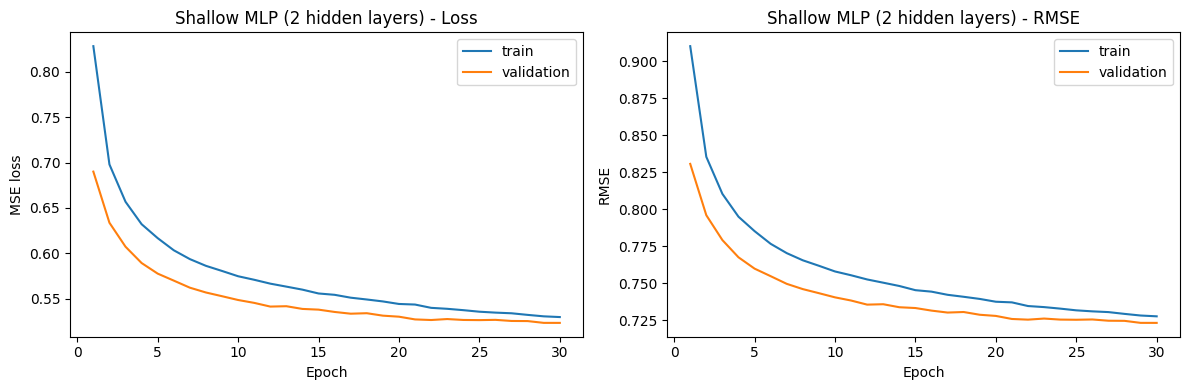

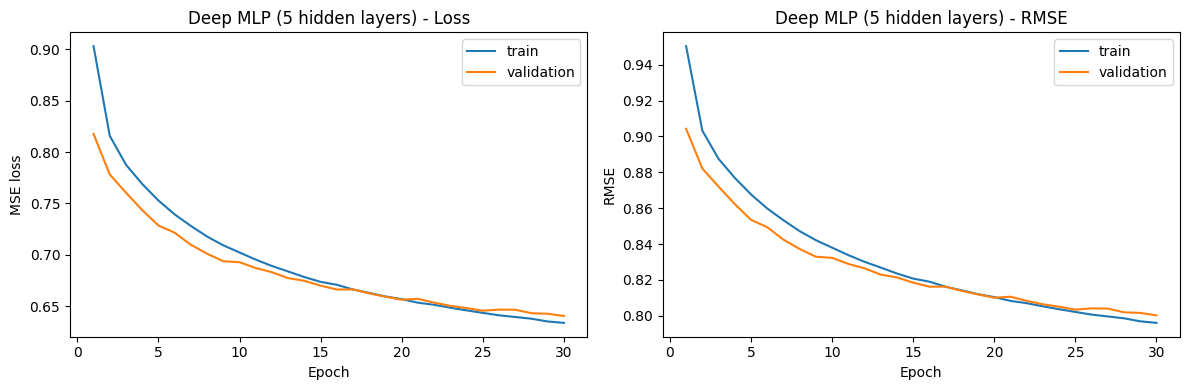

In [10]:
def plot_history(history, title):
  epochs = range(1, len(history["train_loss"]) + 1)
  fig, axes = plt.subplots(1, 2, figsize = (12, 4))

  #training and validation loss vs epoch
  axes[0].plot(epochs, history["train_loss"], label = "train")
  axes[0].plot(epochs, history["val_loss"], label = "validation")
  axes[0].set_title(title + " - Loss")
  axes[0].set_xlabel("Epoch")
  axes[0].set_ylabel(best_loss + " loss")
  axes[0].legend()

  #training and validation performance (RMSE) vs epoch
  axes[1].plot(epochs, history["train_rmse"], label = "train")
  axes[1].plot(epochs, history["val_rmse"], label = "validation")
  axes[1].set_title(title + " - RMSE")
  axes[1].set_xlabel("Epoch")
  axes[1].set_ylabel("RMSE")
  axes[1].legend()

  plt.tight_layout()
  plt.show()

plot_history(shallow_history, "Shallow MLP (2 hidden layers)")
plot_history(deep_history, "Deep MLP (5 hidden layers)")